# 09 · Cierre del Tema 1: calidad global, fichas y las dos tools en dos crisis

Este notebook cierra el Tema 1 (mercados y series numéricas). Junta en un solo sitio lo que han dejado los bloques 1 a 8:

- la **base de series** (`<corpus>/mercados_series/series/base_series.parquet`);
- el **almacén de precios** as-traded (`<corpus>/mercados_series/precios/<proveedor>/`);
- las **fichas** de cada fuente (`results/ingesta/mercados_series/fichas/*.json`);
- las tablas de metadatos (`tablas/cobertura_series.csv` y `tablas/anomalias_series.csv`).

Las salidas muestran **solo metadatos**: recuentos, fechas, métodos, estados y gráficos. No hay tablas de valores
reales: los datos se quedan en local por los términos de las fuentes.

Secciones:

1. Fichas: estado, cobertura y retraso de cada fuente.
2. Cobertura de la base por fuente, método y época.
3. Huecos declarados y anomalías anotadas.
4. Retraso de publicación por método.
5. `get_serie` y `get_precios` el 2008-09-15 (quiebra de Lehman) y el 2020-03-16 (lunes del COVID): qué ven.
6. Truncado: la respuesta en `t` no cambia sin lo publicado después.
7. Conclusiones.

In [1]:
%matplotlib inline
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

from ingesta.mercados_series import almacen, tools

try:
    from regimenes import viz
    viz.use_house_style()
except Exception:  # sin el paquete de la Fase 1: estilo por defecto de matplotlib
    pass
plt.rcParams['figure.dpi'] = 90
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_colwidth', 70)

RAIZ = Path.cwd()
while not (RAIZ / 'pyproject.toml').exists() and RAIZ.parent != RAIZ:
    RAIZ = RAIZ.parent
RES = RAIZ / 'results' / 'ingesta' / 'mercados_series'
FICHAS = {p.stem: json.loads(p.read_text(encoding='utf-8')) for p in sorted((RES / 'fichas').glob('*.json'))}
COB = pd.read_csv(RES / 'tablas' / 'cobertura_series.csv', parse_dates=['inicio', 'fin'])
ANOM = pd.read_csv(RES / 'tablas' / 'anomalias_series.csv', parse_dates=['fecha_referencia'])
COB['prefijo'] = COB['id'].str.split(':').str[0]
ANOM['prefijo'] = ANOM['serie'].str.split(':').str[0]
print(f'{len(FICHAS)} fichas · {len(COB)} series en la tabla de cobertura · {len(ANOM)} anomalías anotadas')

34 fichas · 1434 series en la tabla de cobertura · 582 anomalías anotadas


## 1. Fichas: estado, cobertura y retraso

Una ficha por fuente (o por conjunto: universo, supervivencia, cartera). `estado_sonda` es `ok` si la fuente se ha
descargado y validado entera, `parcial` si falta una parte documentada y `fallo` si no se pudo descargar (por ejemplo,
el veto de `robots.txt`). La cobertura y el retraso están **medidos** en la descarga, no copiados de la web de la fuente.

In [2]:
filas = []
for clave, f in FICHAS.items():
    filas.append({'ficha': clave, 'estado': f.get('estado_sonda'), 'acceso': f.get('acceso'),
                  'inicio': f.get('cobertura_inicio'), 'fin': f.get('cobertura_fin'),
                  'frecuencia': str(f.get('frecuencia') or '')[:40],
                  'retraso': str(f.get('retraso_publicacion') or '')[:70], 'fecha_sonda': f.get('fecha_sonda')})
TF = pd.DataFrame(filas).sort_values(['estado', 'ficha']).reset_index(drop=True)
print(TF['estado'].value_counts().to_string())
TF

estado
ok         29
parcial     4
fallo       1


,ficha,estado,acceso,inicio,fin,frecuencia,retraso,fecha_sonda
0,boe,fallo,descarga,None,None,diaria,no medido (fuente vetada por robots.txt),2026-10-13
1,alfred_vintages,ok,api,1854-12-01,2026-10-07,"mensual, trimestral, semanal, anual y di",medido en ALFRED: días naturales del fin del periodo a la primera ...,2026-10-13
2,bce,ok,api,1995-01-01,2026-10-12,"diaria (FX, €STR, EONIA, tipos oficiales",FX: mismo día 16:00 Berlin (visible en la decisión del día); €STR:...,2026-10-13
3,bce_curvas,ok,api,2004-09-06,2026-10-12,diaria (hábiles del publicador),dato de D publicado a las 12:00 Europe/Berlin del hábil TARGET sig...,2026-10-13
4,binance_vision,ok,descarga,2017-08-17,2026-09-30,"diaria (vela UTC), un ZIP por mes",medido con Last-Modified de 220 ZIP mensuales: mediana 10.03 días ...,2026-10-13
5,bis,ok,api,1945-01-01,2026-09-01,"mensual (CBPOL, EER) y trimestral (brech",sin vintages ni hora: lag fijo conservador desde el fin del period...,2026-10-13
6,boc,ok,api,2001-01-02,2026-10-09,diaria,medido en la sonda: días naturales del último dato a la fecha de l...,2026-10-13
7,boc_curva,ok,api,2001-01-02,2026-10-08,diaria (hábiles del publicador),dato de D publicado el hábil canadiense siguiente; se fija a las 1...,2026-10-13
8,boe_curvas,ok,descarga,1979-01-02,2026-10-12,diaria (hábiles del publicador),dato de D publicado el hábil británico siguiente antes de las 12:0...,2026-10-13
9,boj,ok,api,1998-01-05,2026-10-08,diaria,medido en la sonda: días naturales del último dato a la fecha de l...,2026-10-13


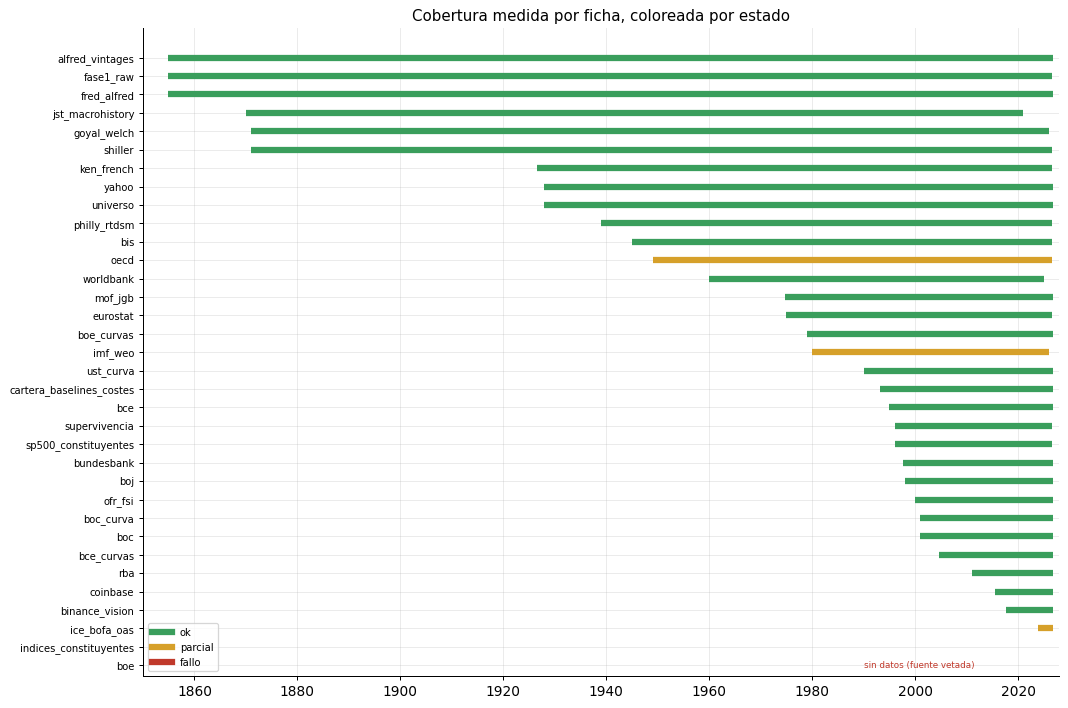

In [3]:
COLOR_ESTADO = {'ok': '#3a9e5c', 'parcial': '#d6a02a', 'fallo': '#c0392b'}
t = TF.assign(i=pd.to_datetime(TF['inicio'].astype(str).str[:10], format='ISO8601', errors='coerce'),
              f=pd.to_datetime(TF['fin'].astype(str).str[:10], format='ISO8601', errors='coerce'))
t = t.sort_values('i', ascending=False, na_position='first').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 8))
for k, r in t.iterrows():
    c = COLOR_ESTADO.get(r['estado'], '#999')
    if pd.notna(r['i']) and pd.notna(r['f']):
        ax.plot([r['i'], r['f']], [k, k], color=c, lw=5, solid_capstyle='butt')
    else:
        ax.text(pd.Timestamp('1990-01-01'), k, 'sin datos (fuente vetada)', va='center', fontsize=7, color=c)
ax.set_yticks(range(len(t)))
ax.set_yticklabels(t['ficha'], fontsize=8)
ax.set_xlim(pd.Timestamp('1850-01-01'), pd.Timestamp('2027-12-31'))
for e, c in COLOR_ESTADO.items():
    ax.plot([], [], color=c, lw=5, label=e)
ax.legend(loc='lower left', fontsize=8)
ax.set_title('Cobertura medida por ficha, coloreada por estado')
plt.tight_layout()
plt.show()

## 2. Cobertura de la base por fuente, método y época

`cobertura_series.csv` resume cada serie de la base (inicio, fin, observaciones, huecos, vintages y retraso). Primero
el reparto por fuente y método de publicación; después cuántas series hay vivas en cada año, por método.

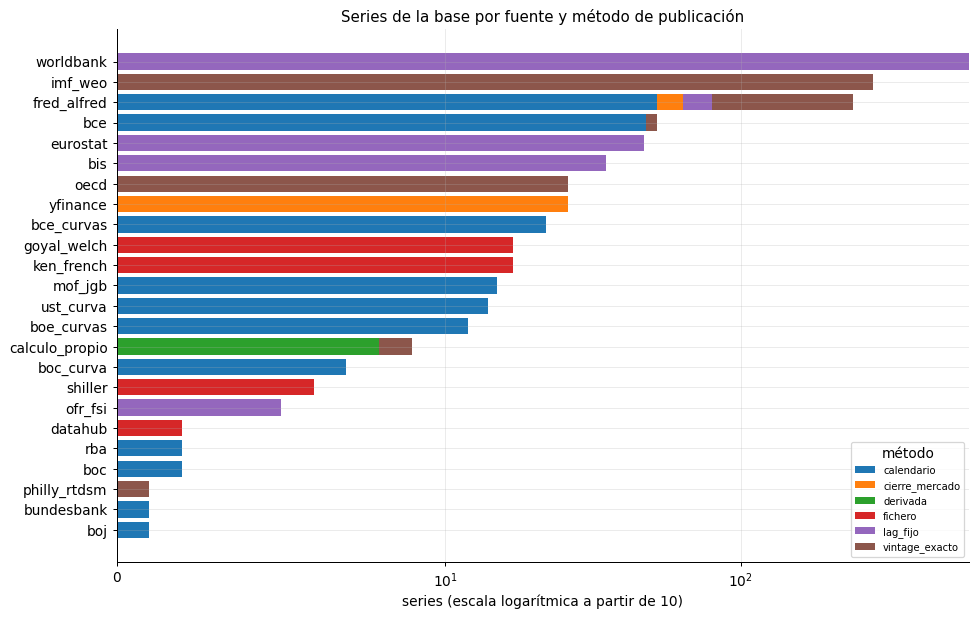

Series por estado: {'activa': 1379, 'retirada': 36, 'duplicada': 11, 'capada': 8}
Series por frecuencia: {'anual': 877, 'diaria': 245, 'mensual': 232, 'trimestral': 67, 'semanal': 13}


In [4]:
fuente_metodo = COB.groupby(['fuente', 'metodo']).size().unstack(fill_value=0)
fuente_metodo = fuente_metodo.loc[fuente_metodo.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(11, 7))
izq = np.zeros(len(fuente_metodo))
for m in fuente_metodo.columns:
    ax.barh(fuente_metodo.index, fuente_metodo[m], left=izq, label=m)
    izq += fuente_metodo[m].to_numpy()
ax.set_xscale('symlog', linthresh=10)
ax.set_xlabel('series (escala logarítmica a partir de 10)')
ax.legend(fontsize=8, title='método')
ax.set_title('Series de la base por fuente y método de publicación')
plt.tight_layout()
plt.show()
print('Series por estado:', COB['estado'].value_counts().to_dict())
print('Series por frecuencia:', COB['frecuencia'].value_counts().to_dict())

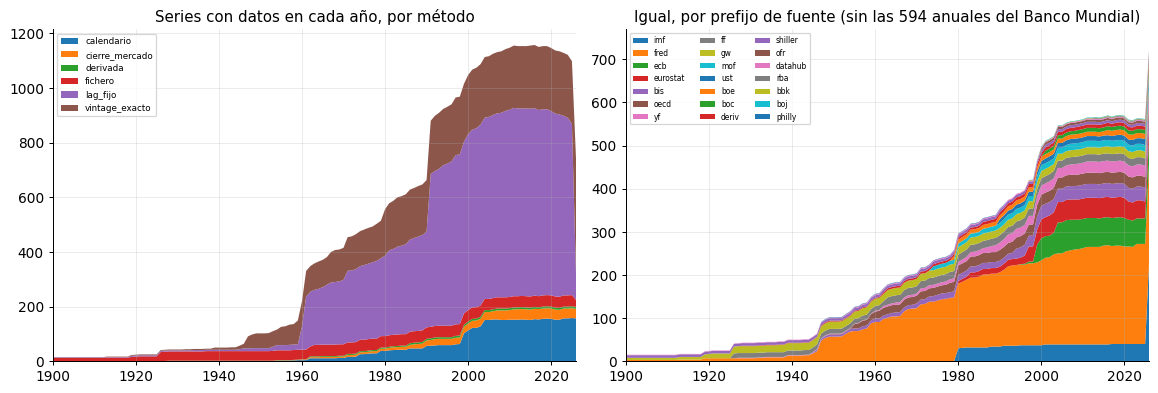

In [5]:
anios = np.arange(1850, 2027)
vivas = {m: [((g['inicio'].dt.year <= a) & (g['fin'].dt.year >= a)).sum() for a in anios]
         for m, g in COB.groupby('metodo')}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].stackplot(anios, *vivas.values(), labels=list(vivas))
axes[0].set_title('Series con datos en cada año, por método')
axes[0].legend(fontsize=7, loc='upper left')
sin_wb = COB[COB['prefijo'] != 'wb']
vivas_f = {p: [((g['inicio'].dt.year <= a) & (g['fin'].dt.year >= a)).sum() for a in anios]
           for p, g in sin_wb.groupby('prefijo')}
orden = sorted(vivas_f, key=lambda p: -max(vivas_f[p]))
axes[1].stackplot(anios, *[vivas_f[p] for p in orden], labels=orden)
axes[1].set_title('Igual, por prefijo de fuente (sin las 594 anuales del Banco Mundial)')
axes[1].legend(fontsize=6, ncol=3, loc='upper left')
for ax in axes:
    ax.set_xlim(1900, 2026)
plt.tight_layout()
plt.show()

## 3. Huecos declarados y anomalías anotadas

Un **hueco** es un periodo que la fuente no publicó (valor nulo con su `nota`, por ejemplo el IPC de octubre de 2025 por
el cierre del Gobierno). Una **anomalía** es un valor que la base conserva tal cual pero anota en la `nota`: picos
aislados que se revierten, cierres en fin de semana y rachas planas largas (posible dato congelado).

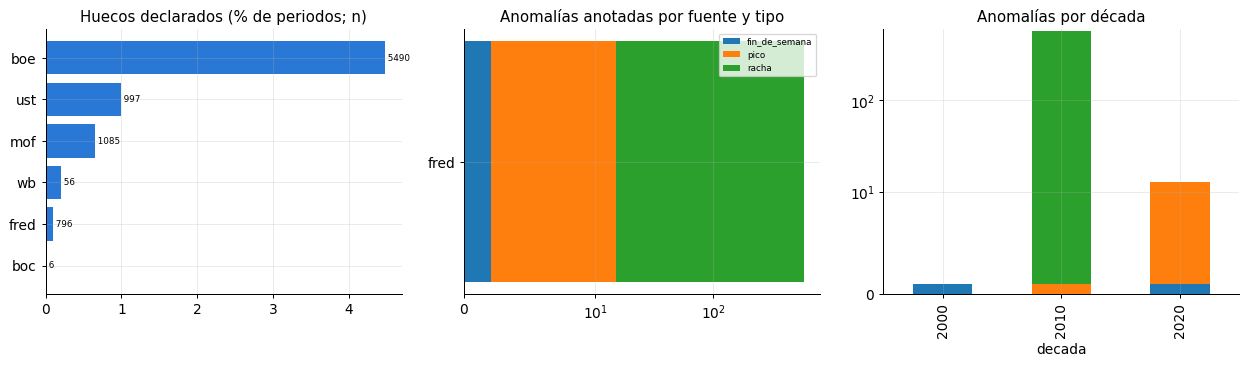

Anomalías por tipo: {'racha': 567, 'pico': 13, 'fin_de_semana': 2}
Series con alguna anomalía: 6


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
h = COB.groupby('prefijo')[['n_obs', 'n_huecos']].sum()
h = h[h['n_huecos'] > 0].assign(pct=lambda d: 100 * d['n_huecos'] / (d['n_obs'] + d['n_huecos'])).sort_values('pct')
axes[0].barh(h.index, h['pct'], color='#2a78d6')
for i, (n, p) in enumerate(zip(h['n_huecos'], h['pct'])):
    axes[0].text(p, i, f' {int(n)}', va='center', fontsize=7)
axes[0].set_title('Huecos declarados (% de periodos; n)')
a = ANOM.groupby(['prefijo', 'tipo']).size().unstack(fill_value=0)
a = a.loc[a.sum(axis=1).sort_values().index]
izq = np.zeros(len(a))
for tipo in a.columns:
    axes[1].barh(a.index, a[tipo], left=izq, label=tipo)
    izq += a[tipo].to_numpy()
axes[1].set_xscale('symlog', linthresh=10)
axes[1].legend(fontsize=7)
axes[1].set_title('Anomalías anotadas por fuente y tipo')
dec = ANOM.assign(decada=(ANOM['fecha_referencia'].dt.year // 10) * 10).groupby(['decada', 'tipo']).size().unstack(fill_value=0)
dec.plot(kind='bar', stacked=True, ax=axes[2], legend=False)
axes[2].set_yscale('symlog', linthresh=10)
axes[2].set_title('Anomalías por década')
plt.tight_layout()
plt.show()
print('Anomalías por tipo:', ANOM['tipo'].value_counts().to_dict())
print('Series con alguna anomalía:', ANOM['serie'].nunique())

Las rachas planas son casi todas legítimas en series administradas (tipos oficiales, tipos de bancos centrales que no se
mueven durante meses); por eso `base.SIN_RACHAS` excluye las de la Fed y la nota solo avisa. Los picos y los cierres en
fin de semana son pocos y se dejan anotados, sin tocar el valor.

## 4. Retraso de publicación por método

`lag_mediano_dias` es la mediana de `fecha_publicacion − fecha_referencia` en cada serie (días naturales). Los cierres
de mercado se ven el mismo día o el siguiente; las series por regla (`lag_fijo`), las de calendario y las vintages
exactas tardan semanas o meses; los ficheros académicos, más.

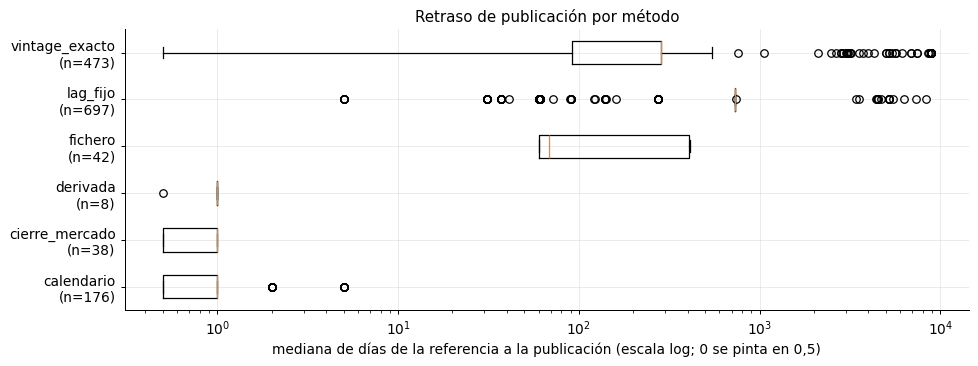

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.2))
grupos = [(m, g['lag_mediano_dias'].dropna().clip(lower=0.5)) for m, g in COB.groupby('metodo')]
ax.boxplot([g for _, g in grupos], tick_labels=[f'{m}\n(n={len(g)})' for m, g in grupos], vert=False)
ax.set_xscale('log')
ax.set_xlabel('mediana de días de la referencia a la publicación (escala log; 0 se pinta en 0,5)')
ax.set_title('Retraso de publicación por método')
plt.tight_layout()
plt.show()

## 5. Las dos tools en dos crisis: qué ven y con qué fecha

Las tools devuelven lo que se sabía a las 16:30 de Nueva York del día pedido. Para cada fecha se muestra **qué** ven
(series y tickers con algo publicado), **hasta qué periodo** llegan, **cuándo** se publicó el último dato y **por qué
método**. No se muestran valores; los gráficos de niveles sí están permitidos.

Primero, toda la base: cuántas series tienen algo publicado en cada fecha (lectura con el filtro de `fecha_publicacion`
en el propio parquet, como hace `almacen.leer_series(hasta=...)`).

In [8]:
FECHAS = ['2008-09-15', '2020-03-16']
for f in FECHAS:
    t0 = time.time()
    vis = pq.read_table(almacen.ruta_series(), columns=['serie', 'metodo_publicacion', 'fecha_publicacion'],
                        filters=[('fecha_publicacion', '<=', pd.Timestamp(f).to_datetime64())]).to_pandas()
    por_metodo = vis.groupby('metodo_publicacion')['serie'].nunique().to_dict()
    print(f'{f}: {vis["serie"].nunique()} series visibles, {len(vis):,} filas ({time.time() - t0:.1f} s) · por método: {por_metodo}')

2008-09-15: 1078 series visibles, 2,049,896 filas (0.6 s) · por método: {'calendario': 155, 'cierre_mercado': 35, 'derivada': 7, 'fichero': 42, 'lag_fijo': 813, 'vintage_exacto': 96}


2020-03-16: 1121 series visibles, 4,613,886 filas (1.1 s) · por método: {'calendario': 165, 'cierre_mercado': 38, 'derivada': 8, 'fichero': 42, 'lag_fijo': 838, 'vintage_exacto': 181}


In [9]:
SERIES = ['fred:PAYEMS', 'fred:UNRATE', 'fred:DGS10', 'fred:VIXCLS', 'deriv:DBAA-DAAA', 'ecb:EXR.D.USD.EUR',
          'ecb:EXR.D.JPY.EUR', 'eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.EA21', 'oecd:CP.DEU', 'oecd:LI_AA.USA',
          'bis:WS_CBPOL.M.US', 'ff:F3M.Mkt-RF', 'shiller:CAPE', 'ust:PAR.10Y', 'philly:ROUTPUT', 'imf:WEO.USA.LUR']
filas = []
for f in FECHAS:
    for s in SERIES:
        try:
            r = tools.get_serie(s, f)
        except KeyError as e:
            filas.append({'fecha': f, 'serie': s, 'visible': False, 'nota': str(e)[:60]})
            continue
        u = r.ultimo()
        filas.append({'fecha': f, 'serie': r.serie, 'visible': True, 'periodos': len(r.datos),
                      'ultimo_periodo': u['fecha_referencia'], 'publicado': u['fecha_publicacion'],
                      'vintage': u['vintage'], 'metodo': u['metodo_publicacion'], 'fuente': r.fuente,
                      'avisos': len(r.avisos)})
META_SERIES = pd.DataFrame(filas)
META_SERIES

,fecha,serie,visible,periodos,ultimo_periodo,publicado,vintage,metodo,fuente,avisos,nota
0,2008-09-15,fred:PAYEMS,True,836.0,2008-08-01,2008-09-05,2008-09-05,vintage_exacto,fred_alfred,0.0,NaN
1,2008-09-15,fred:UNRATE,True,728.0,2008-08-01,2008-09-05,2008-09-05,vintage_exacto,fred_alfred,1.0,NaN
2,2008-09-15,fred:DGS10,True,11659.0,2008-09-12,2008-09-15,unico,calendario,fred_alfred,0.0,NaN
3,2008-09-15,fred:VIXCLS,True,4713.0,2008-09-12,2008-09-13,unico,cierre_mercado,fred_alfred,0.0,NaN
4,2008-09-15,deriv:DBAA-DAAA,True,5710.0,2008-09-12,2008-09-15,unico,derivada,calculo_propio,0.0,NaN
5,2008-09-15,ecb:EXR.D.USD.EUR,True,2485.0,2008-09-15,2008-09-15,unico,calendario,bce,0.0,NaN
6,2008-09-15,ecb:EXR.D.JPY.EUR,True,2485.0,2008-09-15,2008-09-15,unico,calendario,bce,0.0,NaN
7,2008-09-15,eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.EA21,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"""serie 'eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.EA21' sin dato"
8,2008-09-15,oecd:CP.DEU,True,582.0,2008-06-01,2008-09-01,2008-08,vintage_exacto,oecd,1.0,NaN
9,2008-09-15,oecd:LI_AA.USA,True,582.0,2008-06-01,2008-09-01,2008-08,vintage_exacto,oecd,1.0,NaN


Lectura del 2008-09-15: el último empleo y paro visibles son los de agosto (vintage de ALFRED del viernes 5 de
septiembre); H.15 (DGS10) y la curva del Tesoro llegan al viernes 12; el FX del BCE ya trae el fixing del mismo lunes
(16:00 de Fráncfort, antes de las 16:30 de Nueva York). La OCDE (IPC alemán, CLI de EE. UU.) se ve por edición: la de
agosto de 2008, con fecha conservadora a fin de mes, llega hasta junio. El paro de la zona euro de Eurostat va por regla
(`lag_fijo`). Dos casos a tener presentes:

- Ken French y Shiller muestran un vintage de 2026: son ficheros académicos sin ediciones antiguas archivadas, así que
  el valor es el de la primera edición guardada con la fecha de su regla (nota de primera edición: posible fuga de
  revisiones; `get_serie` lo avisa).
- `philly:ROUTPUT` se queda en 1991: solo cubre los vintages anteriores al primero de ALFRED (después manda `fred:GDPC1`).

El WEO del FMI no es visible en ninguna de las dos fechas: solo está cargada la edición 2026-10 y la tool responde como si
el id no existiera (no revela que existirá).

In [10]:
TICKERS = ['SPY', 'AGG', '^GSPC', '^VIX', 'TLT', 'GLD', 'SAP.DE', 'VOD.L', '7203.T', 'EURUSD=X', 'ES=F', 'IBIT']
filas = []
for f in FECHAS:
    r = tools.get_precios(TICKERS, f, ajuste='total', divisa='USD')
    for tk in TICKERS:
        u = r.ultimo(tk)
        filas_tk = r.datos[r.datos['ticker'] == tk]
        n = len(filas_tk)
        filas.append({'fecha': f, 'ticker': tk, 'visible': u is not None, 'sesiones': n,
                      'ultima_sesion': u['sesion'] if u else None, 'publicado': u['fecha_publicacion'] if u else None,
                      'mercado': u['mercado'] if u else None, 'divisa_original': filas_tk['divisa_original'].iloc[-1] if n else None,
                      'fuente': u['fuente'] if u else None})
    print(f'{f}: {len(r.avisos)} avisos; ejemplos: {r.avisos[:2]}')
META_PRECIOS = pd.DataFrame(filas)
META_PRECIOS

2008-09-15: 3 avisos; ejemplos: ["IBIT: sin sesiones publicadas hasta 2008-09-15 (ticker desconocido para 'yahoo' o aún sin datos)", '192 filas en EUR sin fixing del BCE visible en 2008-09-15 anterior o igual a su fecha: valores NaN']


2020-03-16: 3 avisos; ejemplos: ["IBIT: sin sesiones publicadas hasta 2020-03-16 (ticker desconocido para 'yahoo' o aún sin datos)", '192 filas en EUR sin fixing del BCE visible en 2020-03-16 anterior o igual a su fecha: valores NaN']


,fecha,ticker,visible,sesiones,ultima_sesion,publicado,mercado,divisa_original,fuente
0,2008-09-15,SPY,True,3937,2008-09-15,2008-09-15,ARCX,USD,yahoo
1,2008-09-15,AGG,True,1250,2008-09-15,2008-09-15,ARCX,USD,yahoo
2,2008-09-15,^GSPC,True,20266,2008-09-15,2008-09-15,XNYS,USD,yahoo
3,2008-09-15,^VIX,True,4715,2008-09-12,2008-09-13,CBOE_IDX,USD,yahoo
4,2008-09-15,TLT,True,1544,2008-09-15,2008-09-15,XNAS,USD,yahoo
5,2008-09-15,GLD,True,962,2008-09-15,2008-09-15,ARCX,USD,yahoo
6,2008-09-15,SAP.DE,True,2705,2008-09-15,2008-09-15,XETR,EUR,yahoo
7,2008-09-15,VOD.L,True,5168,2008-09-15,2008-09-15,XLON,GBp,yahoo
8,2008-09-15,7203.T,True,2416,2008-09-12,2008-09-12,XTKS,JPY,yahoo
9,2008-09-15,EURUSD=X,True,1226,2008-09-12,2008-09-13,FX_YAHOO,USD,yahoo


El 2020-03-16 las sesiones de Tokio, Xetra y Londres del mismo lunes ya son visibles (cierre local + 30 min antes de
las 16:30 de Nueva York); el VIX (Cboe 16:15), el futuro ES de CME y la divisa de Yahoo, no: llegan al viernes 13
(visibles en D+1). El 2008-09-15 Tokio estaba cerrado (Día del Respeto a los Mayores) y su última sesión es la del 12.
IBIT no existía: el aviso es el mismo que para un ticker desconocido. El aviso de «filas en EUR sin fixing» corresponde a
las sesiones de SAP.DE anteriores a 1999 (el BCE publica desde 1999-01-04): quedan en `NaN` al pasar a USD.

Gráficos de niveles (permitidos): lo que la tool ve en cada fecha en los 120 días anteriores, normalizado a 100 en el
primer día de la ventana.

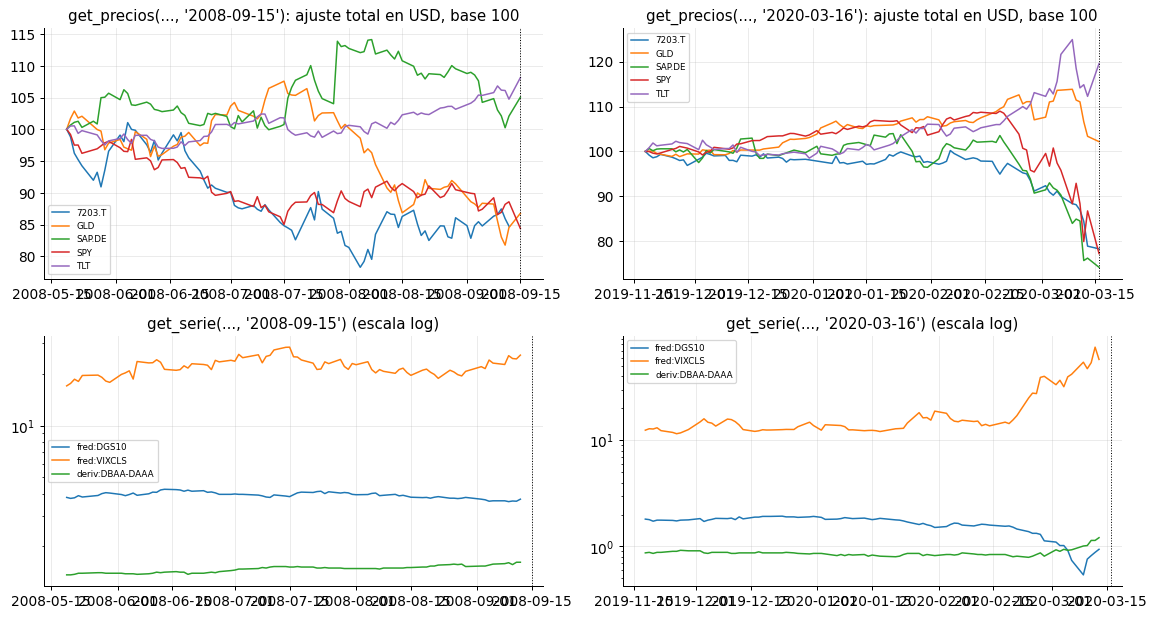

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for j, f in enumerate(FECHAS):
    desde = (pd.Timestamp(f) - pd.Timedelta(days=120)).date().isoformat()
    p = tools.get_precios(['SPY', 'TLT', 'GLD', 'SAP.DE', '7203.T'], f, desde=desde, ajuste='total', divisa='USD').datos
    for tk, g in p.groupby('ticker'):
        axes[0, j].plot(g['sesion'], 100 * g['close'] / g['close'].iloc[0], label=tk, lw=1.2)
    axes[0, j].axvline(pd.Timestamp(f), color='k', ls=':', lw=0.8)
    axes[0, j].set_title(f'get_precios(..., {f!r}): ajuste total en USD, base 100')
    axes[0, j].legend(fontsize=7)
    for s in ['fred:DGS10', 'fred:VIXCLS', 'deriv:DBAA-DAAA']:
        d = tools.get_serie(s, f, desde=desde).datos
        axes[1, j].plot(d['fecha_referencia'], d['valor'], label=s, lw=1.2)
    axes[1, j].axvline(pd.Timestamp(f), color='k', ls=':', lw=0.8)
    axes[1, j].set_yscale('log')
    axes[1, j].set_title(f'get_serie(..., {f!r}) (escala log)')
    axes[1, j].legend(fontsize=7)
plt.tight_layout()
plt.show()

## 6. Truncado: lo que se ve en `t` no depende de lo publicado después

Prueba en directo con las mismas series y tickers: la respuesta por defecto (leída del disco) es idéntica a la que se
obtiene pasando a la tool una base truncada en `t` (sin nada con `fecha_publicacion > t`). La versión completa, con 5
series, 5 tickers y 3 fechas, está en `tests/ingesta/mercados_series/test_t1_cierre.py` (`@pytest.mark.datos`).

In [12]:
resultado = []
for f in FECHAS:
    t = pd.Timestamp(f)
    for s in META_SERIES.loc[META_SERIES['visible'] & (META_SERIES['fecha'] == f), 'serie']:
        completa = almacen.leer_series(s, validar=False)
        a = tools.get_serie(s, f).datos
        b = tools.get_serie(s, f, base=completa[completa['fecha_publicacion'] <= t]).datos
        resultado.append({'fecha': f, 'id': s, 'tool': 'get_serie', 'igual': a.equals(b)})
    precios = pd.concat([almacen.leer_precios(tk) for tk in TICKERS if tk in almacen.tickers_guardados()], ignore_index=True)
    a = tools.get_precios(TICKERS, f, divisa='original').datos
    b = tools.get_precios(TICKERS, f, divisa='original', base=precios[precios['fecha_publicacion'] <= t]).datos
    resultado.append({'fecha': f, 'id': f'{len(TICKERS)} tickers', 'tool': 'get_precios', 'igual': a.equals(b)})
R = pd.DataFrame(resultado)
print(R.groupby(['fecha', 'tool'])['igual'].agg(['sum', 'count']).to_string())
assert R['igual'].all()

                        sum  count
fecha      tool                   
2008-09-15 get_precios    1      1
           get_serie     14     14
2020-03-16 get_precios    1      1
           get_serie     14     14


## 7. Conclusiones

- **Fichas**: la mayoría de las fuentes están en `ok`. Quedan en `parcial` el FMI (solo la edición 2026-10 del WEO: las
  históricas están en DBnomics, que lo veta por `robots.txt`), la OCDE (sin CLI de la zona euro ni paro de China), las
  OAS de ICE BofA (ventana móvil de FRED desde 2023-10-10), la composición actual de índices no estadounidenses (sin
  Nikkei 225 ni Ibovespa) y la cartera (comisiones sin verificar y 1/N con lista estática). El BoE (IADB) está vetado
  por `robots.txt`; sus curvas sí se cargan desde los ficheros publicados.
- **Cobertura**: la base mezcla seis métodos de publicación. Antes de 1960 casi todo son vintages de ALFRED y ficheros
  académicos; la macro internacional y las curvas oficiales empiezan a partir de los noventa.
- **Calidad**: los huecos están todos declarados con nota; las anomalías son sobre todo rachas planas de tipos
  administrados, más un puñado de picos y fechas en fin de semana que se anotan sin tocar el valor.
- **Tools**: en las dos crisis `get_serie` y `get_precios` devuelven solo lo publicado hasta las 16:30 de Nueva York,
  con su fecha de publicación y su método, y la respuesta no cambia al quitar de la base lo publicado después.
- **Pendiente** (detalle en el README del paquete, «Deudas pendientes»): nivel ampliado de precios, horas históricas sin
  verificar, horizontes del SEP, WRDS/CRSP, Tiingo opcional, archivo de ICE y package-data.